# 05 — Drifter time-window sensitivity

**Question:** How many daily inner-core results does each drifter window produce, and how much do the parameters change when satellite observations are included?

Report only days with a result out of the common comparison days, plus parameter time series and differences from the current 48-hour window. No longest-track metric, percentage score, restart procedure or outer-core fitting. Restart the kernel and run in order.

In [1]:
from pathlib import Path
SAVE_OUTPUTS = False
ESP_ROOT = Path('/home/z5297792/ESP_zonodo')
DRIFTER_FILE = ESP_ROOT / 'data/drifter_data.nc'
SATELLITE_FILE = ESP_ROOT / 'data/satellite_data.nc'
WINDOW_HOURS = [3, 6, 9, 12, 15, 18, 21, 24, 27, 30, 33, 36, 39, 42, 45, 48]  # TOTAL durations: 48 means +/-24 hours
REFERENCE_HOURS = 48
SATELLITE_WEIGHT = 0.1  # fixed for the weighted combined run; not swept here
DATA_CUTOFF = '2024-01-27 06:00:00'
CORE_RADIUS_M = 35_000.0  # combined selection, matching the original code
INITIAL_CENTRE_M = (0.0, 0.0)  # original approximate eddy position in this coordinate frame
LON0, LAT0 = 154.3, -37.9
OUTPUT_ROOT = Path('results/05_drifter_window_sensitivity')

**Three configurations:** drifter only; original combined equal-per-observation weighting; and combined with fixed platform-normalised weighting (drifter mean squared error + `SATELLITE_WEIGHT` × satellite mean squared error). The default 0.1 prioritises the drifter platform while allowing satellite support. It is an influence choice, not an error-variance estimate.

Preserve the original examples' inner fitting rules: the drifter-only fit uses all drifter observations in its temporal window; combined fits use the original two-pass 35 km selection with the previous day's ellipse retained between passes. This notebook compares **window sensitivity within each configuration**. Differences between configurations also reflect their spatial-selection rules, not just adding satellite observations. All use the same 06 UTC dates and original velocity processing.

The common comparison period excludes the largest half-window at both ends of the available drifter record. This ensures full archive time coverage for every window, not complete sampling by every drifter. Actual sample/trajectory counts are retained. Each combined run starts independently at the supplied approximate centre with a circular ellipse; later selections depend on its own previous fit.

At the first rejected fit, that run stops. Later days are recorded as **not attempted after failure**, not additional failed fits. No estimate is borrowed from another window/configuration. This implements the requested no-restart comparison; it does not assert that a later independently restarted fit could never succeed.

In [2]:
import hashlib
import json
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import validation_helpers as vh
import platform_weighting as pw
import drifter_weighting as dw
import drifter_windows as windows

if REFERENCE_HOURS not in WINDOW_HOURS:
    raise ValueError('Include REFERENCE_HOURS in WINDOW_HOURS.')
if len(set(WINDOW_HOURS)) != len(WINDOW_HOURS):
    raise ValueError('Use unique window durations.')
backend, backend_info = vh.load_backend(ESP_ROOT)
drifters, satellite, data_info = dw.load_inputs(DRIFTER_FILE,SATELLITE_FILE,DATA_CUTOFF,LON0,LAT0)
times = windows.common_times(drifters,satellite,WINDOW_HOURS)
print('Backend:',backend_info)
print(f'Common comparison: {times[0]} to {times[-1]} UTC ({len(times)} daily dates)')
print('Total window durations (hours):',WINDOW_HOURS)
results = windows.run(backend,drifters,satellite,WINDOW_HOURS,times,
    satellite_weight=SATELLITE_WEIGHT,core_radius=CORE_RADIUS_M,initial_centre=INITIAL_CENTRE_M)
count_table = windows.counts(results)
display(count_table)

Backend: {'path': '/home/z5297792/ESP_zonodo/functions.py', 'sha256': '8e4b06fe4c144f7a70671ee913b6d27784f9cdb587e9b08a2469d82e51be6154', 'python': '3.10.8', 'numpy': '2.2.6', 'pandas': '2.3.3', 'scipy': '1.15.3', 'matplotlib': '3.10.7', 'git_commit': 'a5ce3a7bb9fc21560c3963fc5024db81d6a24184', 'git_status': 'M .ipynb_checkpoints/functions-checkpoint.py\n M __pycache__/functions.cpython-310.pyc\n M functions.py'}
Common comparison: 2023-10-21 06:00:00 to 2024-01-26 06:00:00 UTC (98 daily dates)
Total window durations (hours): [3, 6, 9, 12, 15, 18, 21, 24, 27, 30, 33, 36, 39, 42, 45, 48]


,configuration,window_hours,days_with_result,comparison_days
0,Drifter only,3.0,0,98
1,Combined original,3.0,98,98
2,Combined weighted,3.0,25,98
3,Drifter only,6.0,0,98
4,Combined original,6.0,98,98
5,Combined weighted,6.0,25,98
6,Drifter only,9.0,0,98
7,Combined original,9.0,98,98
8,Combined weighted,9.0,25,98
9,Drifter only,12.0,98,98


A result must have a finite centre/rotation, positive-definite unit-determinant ellipse, sufficient design rank, and the expected cyclonic rotation sign. Combined fits also retain the original 100 km *between-pass refinement* limit. There is no new accuracy or inter-day-jump threshold. A finite accepted result is not proof of accuracy or correct eddy identity.

The denominator includes every common date even if the run stops early. These counts apply to the shared interior period printed above, not the trimmed archive endpoints. Failure reasons and counts are available in `results`; they are not additional headline metrics.

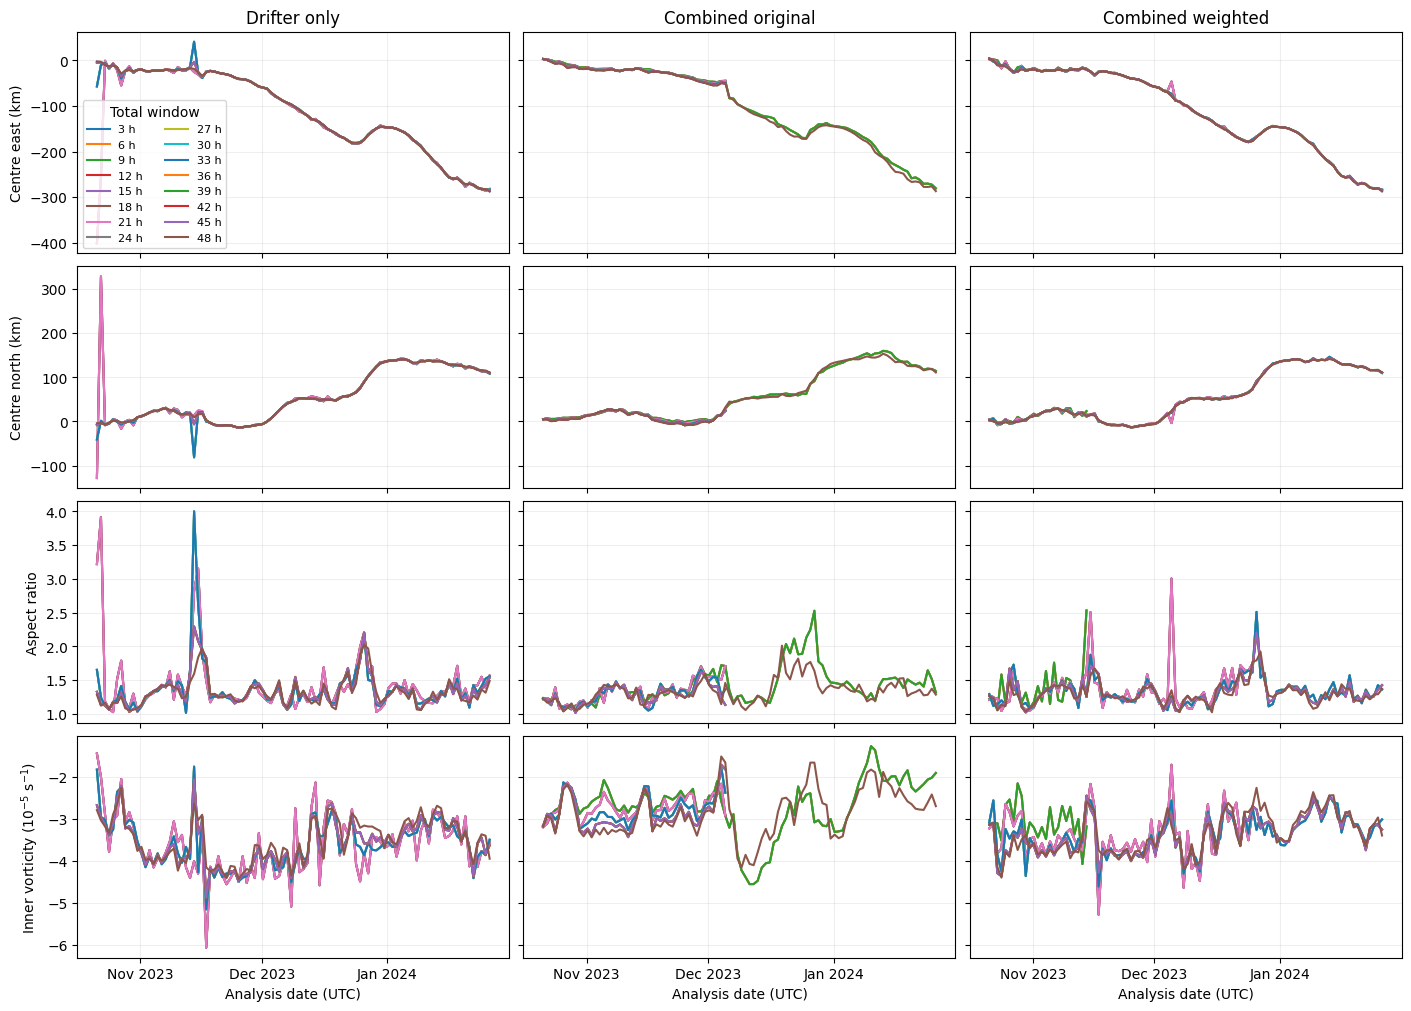

Differences from 48 hours within each configuration; successful matched dates only:


,Configuration,Window (h),Matched days,Median centre change (km),Max centre change (km),Median absolute aspect-ratio change,Median absolute vorticity change (10^-5 s^-1)
0,Drifter only,3.0,0,NaN,NaN,NaN,NaN
1,Drifter only,6.0,0,NaN,NaN,NaN,NaN
2,Drifter only,9.0,0,NaN,NaN,NaN,NaN
3,Drifter only,12.0,98,2.158,417.519,0.068,0.258
4,Drifter only,15.0,98,2.158,417.519,0.068,0.258
5,Drifter only,18.0,98,2.158,417.519,0.068,0.258
6,Drifter only,21.0,98,2.158,417.519,0.068,0.258
7,Drifter only,24.0,98,1.325,108.464,0.051,0.153
8,Drifter only,27.0,98,1.325,108.464,0.051,0.153
9,Drifter only,30.0,98,1.325,108.464,0.051,0.153


In [3]:
fig_parameters = windows.plot_parameters(results)
plt.show()
difference_table = windows.differences(results,REFERENCE_HOURS)
print(f'Differences from {REFERENCE_HOURS:g} hours within each configuration; successful matched dates only:')
display(difference_table.rename(columns={
    'configuration':'Configuration', 'window_hours':'Window (h)', 'matched_days':'Matched days',
    'median_centre_difference_km':'Median centre change (km)',
    'max_centre_difference_km':'Max centre change (km)',
    'median_abs_alpha_difference':'Median absolute aspect-ratio change',
    'median_abs_vorticity_difference_1e5':'Median absolute vorticity change (10^-5 s^-1)'
}).round(3))

Read the table alongside the result counts: a small difference based on very few matched days is not full-period stability. Centre differences are Euclidean distances; aspect-ratio differences are absolute; vorticity differences are in units of 10^-5 s^-1. These are parameter changes, not errors against truth or statistical significance tests. Overlapping windows are correlated.

Longer windows add trajectory coverage but also combine more eddy evolution. Satellite inclusion may help return more estimates, while shifting centre, shape and inner vorticity. The time-series figure makes these trade-offs visible without automatically choosing a best window. No outer radius or refined outer-stage vorticity is estimated here.

In [4]:
if SAVE_OUTPUTS:
    run_dir = OUTPUT_ROOT / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
    run_dir.mkdir(parents=True,exist_ok=False)
    for name,table in [('daily_results',results),('days_with_result',count_table),('parameter_differences',difference_table)]:
        table.to_csv(run_dir/f'{name}.csv',index=False)
    fig_parameters.savefig(run_dir/'parameter_time_series.png',dpi=180,bbox_inches='tight')
    controls = dict(window_hours=WINDOW_HOURS,reference_hours=REFERENCE_HOURS,satellite_weight=SATELLITE_WEIGHT,
        cutoff=DATA_CUTOFF,core_radius_m=CORE_RADIUS_M,initial_centre_m=INITIAL_CENTRE_M,LON0=LON0,LAT0=LAT0,
        comparison_dates=[str(t) for t in times],stop_rule='Stop at first rejected inner fit; no restart.')
    files = [Path(m.__file__) for m in [vh,pw,dw,windows]]+[Path('05_drifter_window_sensitivity.ipynb')]
    provenance = dict(backend=backend_info,data=data_info,controls=controls,
        local_sha256={str(p.resolve()):hashlib.sha256(p.read_bytes()).hexdigest() for p in files})
    (run_dir/'provenance.json').write_text(json.dumps(provenance,indent=2,default=str))
    print('Saved:',run_dir.resolve())
else:
    print('SAVE_OUTPUTS=False: no result files written; Jupyter may still save cell outputs.')

SAVE_OUTPUTS=False: no result files written; Jupyter may still save cell outputs.
